**IMPORTS**

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

**LOAD DATA**

Load the raw survey data from the Excel file into a pandas DataFrame.

In [ ]:
df = pd.read_excel('LifestyleFactorsDataCollection.xlsx')

**CLEAN DATA**

Load the raw survey data from the Excel file into a pandas DataFrame.

In [ ]:
#clean data
df = df.drop(columns= ['Timestamp']) #remove col
df.columns = ['age', 'smoking_status', 'exercise_per_week','average_sleep', 'resting_heart_rate']
df['smoking_status'] = df['smoking_status'].map({'no': 0, 'yes': 1})
df = df[
    (df['resting_heart_rate'] >= 40) & (df['resting_heart_rate'] <=120) &
    (df['average_sleep']>= 3) & (df['average_sleep'] <=12) &
    (df['exercise_per_week']>= 0) & (df['exercise_per_week'] <=7) &
    (df['age']>= 15) & (df['age'] <=60)]

**SELECT FEATURES**

Select the features to use for clustering

In [ ]:
x = df[['exercise_per_week', 'average_sleep', 'smoking_status', 'resting_heart_rate']]

SCALE FEATURES

Standardize all features so they're on the same scale, then increase the
weight of resting_heart_rate since it's the most important factor for this analysis.


In [ ]:
#give more weight to resting_heart_rate
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)
x_scaled[:,3] = x_scaled[:,3]*1.5


**FIND OPTIMAL NUM OF CLUSTERS**

used the elbow methid to determine the best number of clusters for K-Means.

Text(0.5, 1.0, 'elbow method')

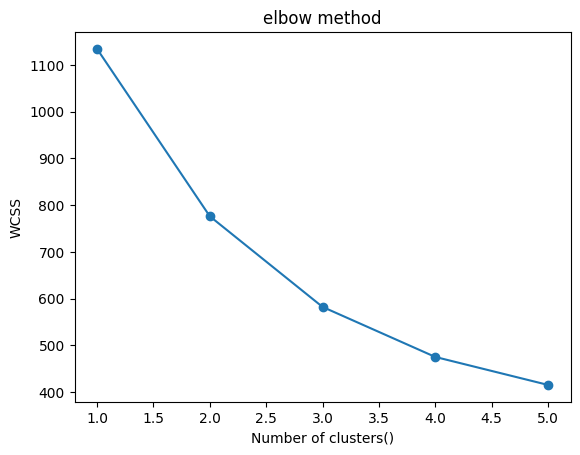

In [ ]:
wcss = []
for k in range(1,6):
  kmeans = KMeans(n_clusters=k, random_state=50)
  kmeans.fit(x_scaled)
  wcss.append(kmeans.inertia_)
plt.plot(range(1,6), wcss, marker = 'o')
plt.xlabel('Number of clusters()')
plt.ylabel('WCSS')
plt.title('elbow method')

**FIT K-MEANS WITH K=3**

The elbow chart showed 3 is a good number of groups to use. Here we actually run K-Means with 3 clusters and label every person in the dataset with which group (0, 1, or 2) they belong to.

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=50)
kmeans.fit(x_scaled)
df['cluster'] = kmeans.labels_

**CENTROIDS**

In [ ]:

centroids_scaled = kmeans.cluster_centers_
centroids_original = scaler.inverse_transform(centroids_scaled)
centroids_df = pd.DataFrame(centroids_original, columns= ['excersise_per_week', 'average_sleep', 'smoking_status', 'resting_heart_rate'])
print('centroids')
print(centroids_df.round(2))

centroids
   excersise_per_week  average_sleep  smoking_status  resting_heart_rate
0                2.15           7.04            -0.0               77.88
1                4.51           7.38             0.0               54.96
2                2.29           6.17             1.0               78.15


**PLOTTING THE CLUSTERS**

Scatter plot of average sleep vs resting heart rate, colored by cluster,
so we can see the groups visually

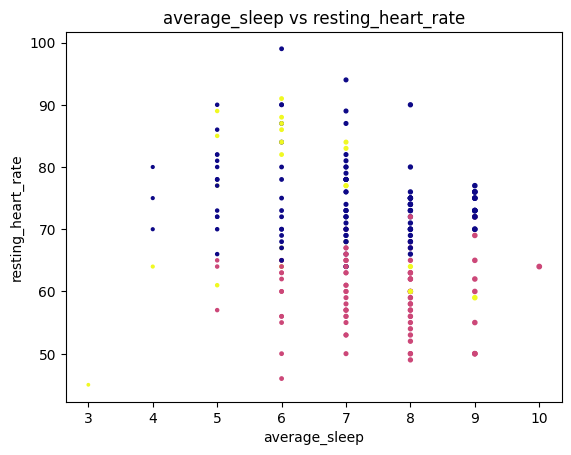

In [ ]:
plt.scatter(df['average_sleep'], df['resting_heart_rate'], df['average_sleep'],c = df ['cluster'], cmap = 'plasma')
plt.xlabel('average_sleep')
plt.ylabel('resting_heart_rate')
plt.title('average_sleep vs resting_heart_rate')
plt.show()